In [ ]:
!pip install praw

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 191.0/191.0 kB 3.6 MB/s eta 0:00:00


In [ ]:
import praw
import pprint
import pandas as pd
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk import ngrams
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk import word_tokenize

import re  # For regular expressions
from collections import Counter
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

In [ ]:
# Reddit API credentials
APP_ID = "YOUR-API-KEY"
APP_SECRECT = "YOUR-SECRECT"


reddit = praw.Reddit(client_id=APP_ID,
                     client_secret=APP_SECRECT,
                     user_agent="Comment Extraction")


In [ ]:
subreddits = ['cars', 'askcarguys', 'projectcar', 'whatcarshouldIbuy', 'electricvehicles']
search_query = "car"
max_comments = 2000
all_comments = []

for subreddit_name in subreddits:
    subreddit = reddit.subreddit(subreddit_name)
    for submission in subreddit.search(search_query, limit=1000):
        submission.comments.replace_more(limit=None)
        for comment in submission.comments.list():
            all_comments.append([comment.body, comment.created_utc])
            if len(all_comments) >= max_comments:
                break  # Exit the inner loop if enough comments are collected
        if len(all_comments) >= max_comments:
            break  # Exit the outer loop if enough comments are collected

It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.

It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.

It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.

It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.

It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/l

In [ ]:
print(all_comments)

[["Some are still doing okay from what I've seen but yeah, ofc it has died out due to everything you've mentioned. \n\nThe worst part, is seeing images deleted from 18 yr old posts when it was exactly what trouble shooting you needed lol", 1726274957.0], ['Remember when you found a new forum to hang out and discover the builds section, where you spent hours and hours looking at all the builds and the evolution of thoses projects? I miss it too. It was fantastic.', 1726275320.0], ['Facebook and Reddit have killed almost every hobby message board and it makes me sad. At least 80% of what I know about cars, airplanes, guns, and woodworking can be attributed to reading message boards in the 2000s.', 1726275989.0], ['We’ve shifted to more engagement friendly forums where a bunch of kids with no cars at all can argue endlessly about a YouTube video they saw.\xa0', 1726274996.0], ['You aren\'t going to acknowledge Reddit\'s part in all of that? \n\nI usually describe Reddit to those not famil

In [ ]:
total_data = len(all_comments)
print("Total data in all_comments:", total_data)


Total data in all_comments: 2004


In [ ]:
df = pd.DataFrame(all_comments, columns=['Comment', 'Timestamp'])


In [ ]:
df.head()

,Comment,Timestamp
0,Some are still doing okay from what I've seen ...,1.726275e+09
1,Remember when you found a new forum to hang ou...,1.726275e+09
2,Facebook and Reddit have killed almost every h...,1.726276e+09
3,We’ve shifted to more engagement friendly foru...,1.726275e+09
4,You aren't going to acknowledge Reddit's part ...,1.726277e+09


In [ ]:
df.shape[0]

2004

In [ ]:
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')

def preprocess_text(text):
    # Cleaning
    text = re.sub(r'https?:\/\/.*[\r\n]*', '', text)  # Remove URLs
    text = re.sub(r'[^A-Za-z0-9\s#]', '', text)  # Remove some symbols
    text = text.lower()

    # Tokenization
    words = nltk.word_tokenize(text)

    # Stop word removal
    stop_words = set(stopwords.words('english'))
    words = [w for w in words if w not in stop_words]

    # Lemmatization
    lemmatizer = WordNetLemmatizer()
    words = [lemmatizer.lemmatize(w) for w in words]

    return ' '.join(words)

df['Processed_Comment'] = df['Comment'].apply(preprocess_text)


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [ ]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2004 entries, 0 to 2003
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Comment            2004 non-null   object 
 1   Timestamp          2004 non-null   float64
 2   Processed_Comment  2004 non-null   object 
dtypes: float64(1), object(2)
memory usage: 47.1+ KB


,Comment,Timestamp,Processed_Comment
0,Some are still doing okay from what I've seen ...,1.726275e+09,still okay ive seen yeah ofc died due everythi...
1,Remember when you found a new forum to hang ou...,1.726275e+09,remember found new forum hang discover build s...
2,Facebook and Reddit have killed almost every h...,1.726276e+09,facebook reddit killed almost every hobby mess...
3,We’ve shifted to more engagement friendly foru...,1.726275e+09,weve shifted engagement friendly forum bunch k...
4,You aren't going to acknowledge Reddit's part ...,1.726277e+09,arent going acknowledge reddits part usually d...


# Exploratory

**Group** comments by month and count the number of comments

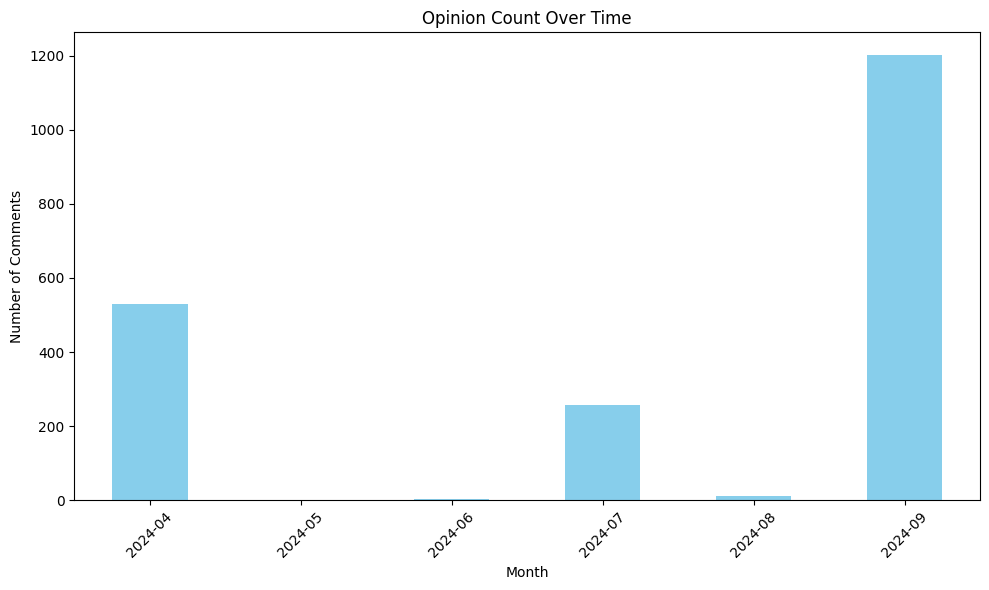

In [ ]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'], unit='s')
df['Month'] = df['Timestamp'].dt.to_period('M')
df_grouped_month = df.groupby('Month')['Comment'].count()

# Plot comments count over the months
plt.figure(figsize=(10, 6))
df_grouped_month.plot(kind='bar', color='skyblue')
plt.xlabel('Month')
plt.ylabel('Number of Comments')
plt.title('Opinion Count Over Time')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

# Calculate mean, mode, and standard deviation of comment lengths
comment_lengths = df['Processed_Comment'].str.len()
mean_length = comment_lengths.mean()
mode_length = comment_lengths.mode()[0]  # Mode can have multiple values, taking the first one
std_dev_length = comment_lengths.std()

print("Mean comment length:", mean_length)
print("Mode comment length:", mode_length)
print("Standard deviation of comment length:", std_dev_length)


Mean comment length: 127.95359281437126
Mode comment length: 7
Standard deviation of comment length: 159.27194358720183


Top Words :
       Word  Frequency
0      car       1071
1   people        439
2     like        417
3    forum        351
4      one        278
5      get        262
6     dont        238
7    still        230
8     even        198
9     year        190
10    make        183
11   would        182
12    time        181
13      im        173
14    much        170
15   thing        162
16   think        156
17     lot        140
18   never        135
19   tesla        135



Top Bigrams:

                Bigram  Frequency
0    (social, medium)         89
1        (small, car)         54
2      (car, culture)         53
3        (car, forum)         45
4         (year, ago)         40
5          (new, car)         30
6   (facebook, group)         26
7        (feel, like)         22
8        (dont, know)         22
9         (year, old)         22
10       (real, life)         22
11         (im, sure)         20
12         (20, year)         19
13      (dont, think)         19
14   (messag

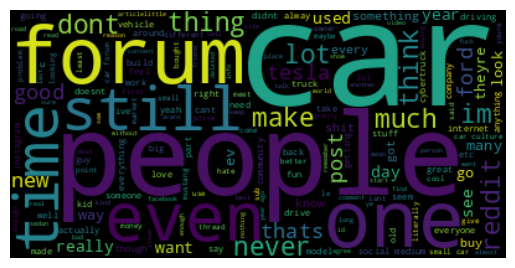

In [ ]:
# Word Frequencies
all_words = ' '.join(df['Processed_Comment']).split()
word_counts = Counter(all_words)

top_words = pd.DataFrame(word_counts.most_common(20), columns=['Word', 'Frequency'])
print("Top Words :\n" , top_words)

# N-Grams (example: Bigrams)
bigrams = ngrams(all_words, 2)
bigram_counts = Counter(bigrams)

top_bigrams = pd.DataFrame(bigram_counts.most_common(15), columns=['Bigram', 'Frequency'])
print("\n\n")
print("Top Bigrams:\n\n" ,top_bigrams)
print("\n\n")
# Word Cloud
comment_text = ' '.join(df['Processed_Comment'])
wordcloud = WordCloud(stopwords=STOPWORDS).generate(comment_text)
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()

In [ ]:
nltk.download('vader_lexicon')
analyzer = SentimentIntensityAnalyzer()

def analyze_sentiment(comment):
    scores = analyzer.polarity_scores(comment)
    sentiment = 'Positive' if scores['compound'] >= 0.05 else 'Negative' if scores['compound'] <= -0.05 else 'Neutral'
    return sentiment, scores

def extract_keywords(comment, sentiment):
    if sentiment != 'Neutral':  # Focus on strong sentiments
        words = word_tokenize(comment)
        return words
    return []

df['Sentiment'], df['Scores'] = zip(*df['Processed_Comment'].apply(analyze_sentiment))
df['Keywords'] = df.apply(lambda row: extract_keywords(row['Processed_Comment'], row['Sentiment']), axis=1)

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [ ]:
print(df.columns)
df.head()

Index(['Comment', 'Timestamp', 'Processed_Comment', 'Month', 'Sentiment',
       'Scores', 'Keywords'],
      dtype='object')


,Comment,Timestamp,Processed_Comment,Month,Sentiment,Scores,Keywords
0,Some are still doing okay from what I've seen ...,2024-09-14 00:49:17,still okay ive seen yeah ofc died due everythi...,2024-09,Negative,"{'neg': 0.287, 'neu': 0.523, 'pos': 0.19, 'com...","[still, okay, ive, seen, yeah, ofc, died, due,..."
1,Remember when you found a new forum to hang ou...,2024-09-14 00:55:20,remember found new forum hang discover build s...,2024-09,Positive,"{'neg': 0.075, 'neu': 0.755, 'pos': 0.17, 'com...","[remember, found, new, forum, hang, discover, ..."
2,Facebook and Reddit have killed almost every h...,2024-09-14 01:06:29,facebook reddit killed almost every hobby mess...,2024-09,Negative,"{'neg': 0.345, 'neu': 0.655, 'pos': 0.0, 'comp...","[facebook, reddit, killed, almost, every, hobb..."
3,We’ve shifted to more engagement friendly foru...,2024-09-14 00:49:56,weve shifted engagement friendly forum bunch k...,2024-09,Positive,"{'neg': 0.129, 'neu': 0.538, 'pos': 0.333, 'co...","[weve, shifted, engagement, friendly, forum, b..."
4,You aren't going to acknowledge Reddit's part ...,2024-09-14 01:15:42,arent going acknowledge reddits part usually d...,2024-09,Positive,"{'neg': 0.07, 'neu': 0.545, 'pos': 0.384, 'com...","[arent, going, acknowledge, reddits, part, usu..."


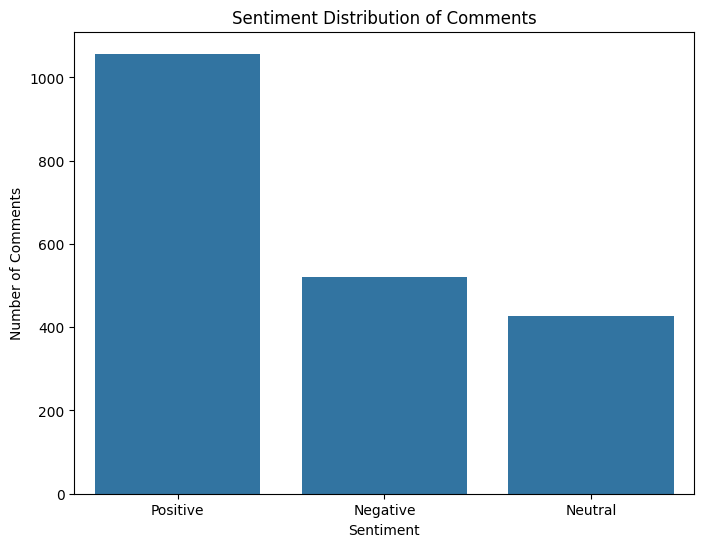

Sentiment Percentages:
 Sentiment
Positive    52.744511
Negative    25.948104
Neutral     21.307385
Name: count, dtype: float64


In [ ]:

# Polarity Distribution
sentiment_counts = df['Sentiment'].value_counts()
plt.figure(figsize=(8, 6))
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values)
plt.xlabel('Sentiment')
plt.ylabel('Number of Comments')
plt.title('Sentiment Distribution of Comments')
plt.show()

# Percentage Distribution
total_comments = len(df)
sentiment_percentages = (sentiment_counts / total_comments) * 100
print("Sentiment Percentages:\n", sentiment_percentages)


Fuel_Type
unknown     1315
electric     658
gas           20
diesel         8
hybrid         3
Name: count, dtype: int64


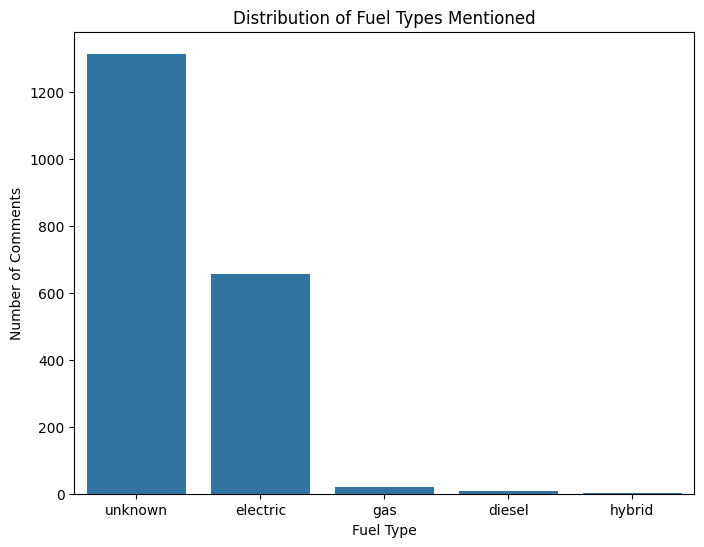

In [ ]:

# Feature Extraction - Fuel Type

def extract_fuel_type(comment):
  # Simple keyword-based extraction
  fuel_keywords = {
      "gas": ["gas", "gasoline", "petrol"],
      "diesel": ["diesel"],
      "electric": ["electric", "ev", "tesla", "battery"],
      "hybrid": ["hybrid"]
  }

  for fuel_type, keywords in fuel_keywords.items():
    for keyword in keywords:
      if keyword in comment.lower():
        return fuel_type
  return "unknown"  # If no fuel type is detected

df['Fuel_Type'] = df['Processed_Comment'].apply(extract_fuel_type)

# Analyze distribution of fuel types
fuel_type_counts = df['Fuel_Type'].value_counts()
print(fuel_type_counts)

# Visualization (optional)
plt.figure(figsize=(8, 6))
sns.barplot(x=fuel_type_counts.index, y=fuel_type_counts.values)
plt.xlabel('Fuel Type')
plt.ylabel('Number of Comments')
plt.title('Distribution of Fuel Types Mentioned')
plt.show()


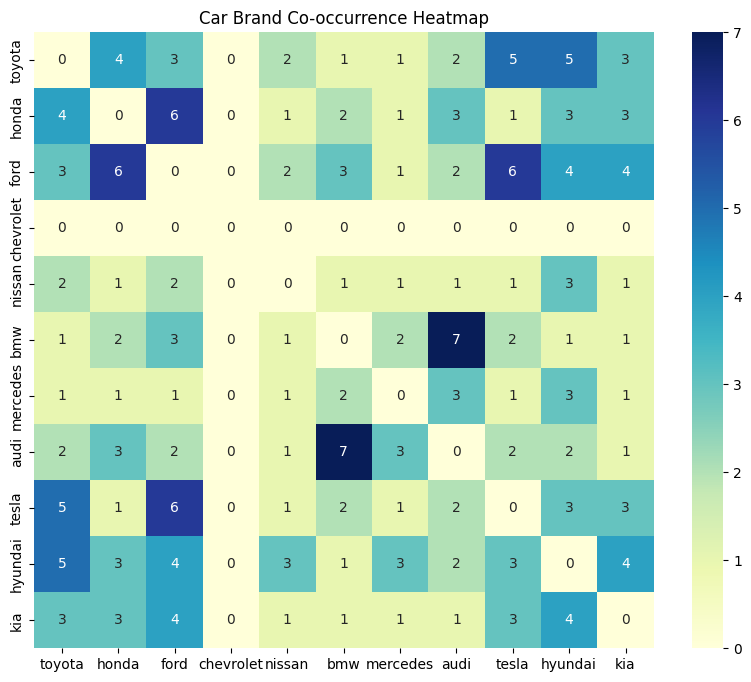

In [ ]:
#Heatmap of different car brands
car_brands = ["toyota", "honda", "ford", "chevrolet", "nissan",
                  "bmw", "mercedes", "audi", "tesla", "hyundai", "kia"]

# Feature Extraction - Car Brands
def extract_car_brands(comment):
    found_brands = []
    for brand in car_brands:
        if brand in comment.lower():
            found_brands.append(brand)
    return found_brands

df['Car_Brands'] = df['Processed_Comment'].apply(extract_car_brands)

# Create a brand co-occurrence matrix
brand_cooccurrence = pd.DataFrame(0, index=car_brands, columns=car_brands)

for brands in df['Car_Brands']:
    for brand1 in brands:
        for brand2 in brands:
            if brand1 != brand2:
                brand_cooccurrence.loc[brand1, brand2] += 1

# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(brand_cooccurrence, annot=True, cmap="YlGnBu")
plt.title("Car Brand Co-occurrence Heatmap")
plt.show()


# Sentiment Plot

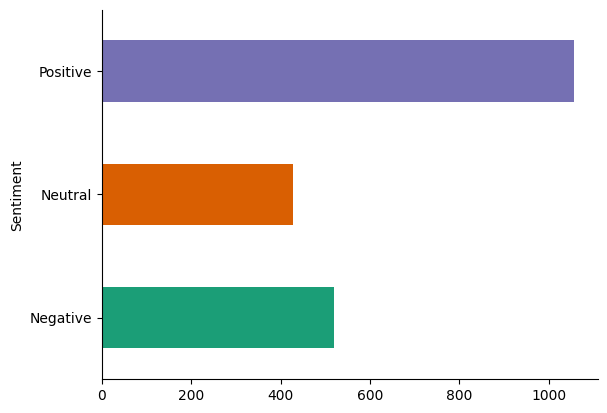

In [ ]:
df.groupby('Sentiment').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

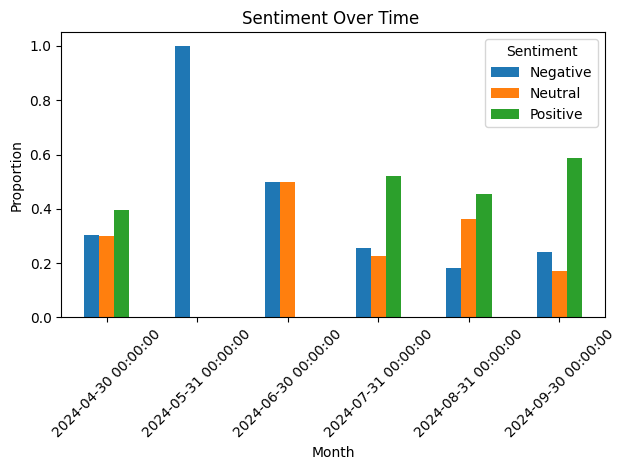

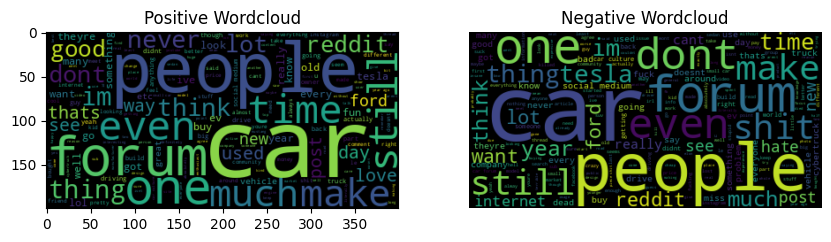

In [ ]:
# Convert timestamp to datetime
df['Timestamp'] = pd.to_datetime(df['Timestamp'], unit='s')

# Group by Month
df_grouped = df.groupby(pd.Grouper(key='Timestamp', freq='M'))['Sentiment'].value_counts(normalize=True).unstack()

df_grouped = df_grouped.fillna(0)  # Fill NaN with 0 for plotting proportions
df_grouped.plot(kind='bar')
plt.xlabel('Month')
plt.ylabel('Proportion')
plt.title('Sentiment Over Time ')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Word Clouds
from wordcloud import WordCloud, STOPWORDS
positive_words = ' '.join(word for keywords_list in df[df['Sentiment'] == 'Positive']['Keywords'] for word in keywords_list)
negative_words = ' '.join(word for keywords_list in df[df['Sentiment'] == 'Negative']['Keywords'] for word in keywords_list)


wordcloud_pos = WordCloud(stopwords=STOPWORDS).generate(positive_words)
wordcloud_neg = WordCloud(stopwords=STOPWORDS).generate(negative_words)

# Plot them
plt.figure(figsize=(10,6))
plt.subplot(1,2,1)
plt.imshow(wordcloud_pos, interpolation='bilinear')
plt.title('Positive Wordcloud')
plt.subplot(1,2,2)
plt.imshow(wordcloud_neg, interpolation='bilinear')
plt.title('Negative Wordcloud')
plt.axis("off")
plt.show()

In [ ]:
#Topic Modelling
import gensim
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel

# Prepare the text data
texts = [text.split() for text in df['Processed_Comment']]

# Create a dictionary and corpus
dictionary = corpora.Dictionary(texts)
corpus = [dictionary.doc2bow(text) for text in texts]

# Build the LDA model
num_topics = 5
lda_model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=num_topics, random_state=42)

# Print the topics
for idx, topic in lda_model.print_topics(-1):
    print(f"Topic: {idx} \nWords: {topic}\n")

# Evaluate the model
coherence_model_lda = CoherenceModel(model=lda_model, texts=texts, dictionary=dictionary, coherence='c_v')
coherence_lda = coherence_model_lda.get_coherence()
print(f"\nCoherence Score: {coherence_lda}")


Topic: 0 
Words: 0.100*"trailer" + 0.030*"house" + 0.024*"stuff" + 0.021*"got" + 0.020*"show" + 0.020*"parked" + 0.020*"stack" + 0.019*"pointed" + 0.016*"bringing" + 0.016*"writing"

Topic: 1 
Words: 0.041*"knock" + 0.039*"eu" + 0.027*"load" + 0.025*"ok" + 0.024*"little" + 0.022*"add" + 0.020*"dead" + 0.020*"total" + 0.018*"say" + 0.017*"stuff"

Topic: 2 
Words: 0.039*"car" + 0.033*"stuff" + 0.021*"house" + 0.021*"allow" + 0.020*"half" + 0.019*"loaded" + 0.018*"lived" + 0.014*"got" + 0.014*"electric" + 0.014*"gas"

Topic: 3 
Words: 0.043*"charger" + 0.029*"blanket" + 0.029*"payment" + 0.027*"mad" + 0.022*"law" + 0.021*"every" + 0.019*"end" + 0.018*"lived" + 0.018*"fast" + 0.014*"trailer"

Topic: 4 
Words: 0.062*"neighbor" + 0.032*"card" + 0.032*"allow" + 0.029*"device" + 0.026*"must" + 0.023*"youre" + 0.023*"driveway" + 0.020*"ev" + 0.019*"highway" + 0.015*"without"


Coherence Score: 0.48983678280485954


# Non-Negative Factorization

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

# Convert text data into a TF-IDF matrix
tfidf_vectorizer = TfidfVectorizer(max_features=1000, lowercase=True, stop_words='english')
tfidf = tfidf_vectorizer.fit_transform(df['Processed_Comment'])

# Apply NMF
nmf = NMF(n_components=10, random_state=42)
nmf.fit(tfidf)

# Print topics
feature_names = tfidf_vectorizer.get_feature_names_out()
for topic_idx, topic in enumerate(nmf.components_):
    print(f"Topic {topic_idx + 1}:")
    print([feature_names[i] for i in topic.argsort()[:-11:-1]])
    print()


Topic 1:
['car', 'culture', 'small', 'new', 'love', 'fun', 'enthusiast', 'driving', 'cool', 'expensive']

Topic 2:
['deleted', 'instagram', 'life', 'image', 'post', 'better', 'way', 'shooting', 'trouble', 'mass']

Topic 3:
['removed', 'domain', 'argument', 'wrong', 'thats', 'spam', 'source', 'link', 'unfortunately', 'different']

Topic 4:
['forum', 'miss', 'reddit', 'facebook', 'group', 'alive', 'active', 'use', 'search', 'post']

Topic 5:
['people', 'like', 'dont', 'think', 'medium', 'social', 'thing', 'reddit', 'shit', 'real']

Topic 6:
['ford', 'focus', 'small', 'st', 'make', 'fiesta', 'want', 'vehicle', 'truck', 'bring']

Topic 7:
['bot', 'automatically', 'concern', 'contact', 'subredditmessagecomposetorcars', 'performed', 'action', 'moderator', 'question', 'welcomei']

Topic 8:
['tesla', 'ev', 'truck', 'elon', 'cybertruck', 'sub', 'start', 'company', 'musk', 'going']

Topic 9:
['year', 'time', 'im', 'good', 'day', 'ago', 'old', 'got', 'build', 'used']

Topic 10:
['lol', 'yeah', 'l